In [4]:
import gymnasium as gym
from stable_baselines3 import PPO
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

# wind turbine environment

In [5]:


import gymnasium as gym
from gymnasium import spaces

import numpy as np


class WindTurbineEnv(gym.Env):
    """
    Wind turbine digital twin environment
    RL controls yaw velocity
    timestep:
        dt = 1 second
    """

    def __init__(self):
        super().__init__()
        # -------------------------
        # Simulation parameters
        # -------------------------

        self.dt = 1.0     # seconds

        # Turbine parameters
        self.rho = 1.225        # air density
        self.radius = 40        # rotor radius
        self.area = np.pi*self.radius**2

        self.Cp = 0.42          # power coefficient

        # yaw actuator
        self.max_yaw_speed = 1.0  # deg/sec
        
        # Observation space      
        # [wind speed,wind direction,yaw angle,yaw error,power]

        low=np.array([3,0,0,-180,0],dtype=np.float32)

        high=np.array([20,360,360,180,10e6],dtype=np.float32)

        self.observation_space = spaces.Box(low,high,dtype=np.float32)
        
        # Action      

        # yaw velocity command
        #
        # -1 deg/s to +1 deg/s

        self.action_space = spaces.Box(
            low=np.array([-1]),
            high=np.array([1]),
            dtype=np.float32
        )
        self.reset()
    

    def reset(self,seed=None,options=None):
        super().reset(seed=seed)
        self.time=0
        self.wind_speed=np.random.uniform(5,12)

        self.wind_direction=np.random.uniform(0,360)

        self.yaw=np.random.uniform(0,360)

        self.power=0
        obs=self.get_state()
        return obs,{}

    

    def wind_model(self):
        """
        Wind simulator
        speed:
        3-20 m/s
        direction:
        0-360 deg
        """
        self.wind_speed = (10+5*np.sin(0.002*self.time)+np.random.normal(0,0.2))

        self.wind_speed=np.clip(self.wind_speed,3,20)

        self.wind_direction += (0.5*np.sin(0.01*self.time)+np.random.normal(0,1))

        self.wind_direction %=360

    def turbine_power(self):
        yaw_error = (self.wind_direction-self.yaw)

        # convert to -180 to 180
        yaw_error = (yaw_error+180)%360-180

        yaw_rad=np.deg2rad(yaw_error)

        # Power equation
        power=(0.5*self.rho*self.area*self.Cp*self.wind_speed**3*np.cos(yaw_rad)**3)

        return max(power,0)


    def get_state(self):

        error=(self.wind_direction-self.yaw)
        error=(error+180)%360-180

        return np.array([self.wind_speed,self.wind_direction,self.yaw,error,self.power/1e6],dtype=np.float32)


    def step(self,action):
        self.time += self.dt

        # yaw actuator    
        yaw_velocity=float(action[0])
        self.yaw += (yaw_velocity*self.dt)
        self.yaw %=360
       
        # wind update      
        self.wind_model()
       
        # power generation       
        self.power=self.turbine_power()

        yaw_error=(self.wind_direction-self.yaw)
        yaw_error=(yaw_error+180)%360-180
        
        # reward    
        reward=(self.power/1e6-0.05*abs(yaw_error)-0.02*abs(yaw_velocity))

        obs=self.get_state()

        terminated=False

        truncated=False

        return (obs,reward,terminated,truncated,{})


# train PPO

In [6]:

from stable_baselines3 import PPO

env=WindTurbineEnv()

model=PPO(

    policy="MlpPolicy",
    env=env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    gamma=0.99,
    verbose=1
)

model.learn(
    total_timesteps=300000
)



model.save(
    "ppo_yaw_controller"
)

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
-----------------------------
| time/              |      |
|    fps             | 1807 |
|    iterations      | 1    |
|    time_elapsed    | 1    |
|    total_timesteps | 2048 |
-----------------------------
------------------------------------------
| time/                   |              |
|    fps                  | 1248         |
|    iterations           | 2            |
|    time_elapsed         | 3            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0030398546 |
|    clip_fraction        | 0.0115       |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.42        |
|    explained_variance   | 0.00363      |
|    learning_rate        | 0.0003       |
|    loss                 | 589          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.00139     |
|    std

# Test

In [7]:


env=WindTurbineEnv()

model=PPO.load("ppo_yaw_controller")

obs,_=env.reset()

speed=[]
direction=[]
yaw=[]
error=[]
power=[]
energy=[]
total_reward=[]



total_energy=0
dt = env.dt


for t in range(1000):


    action,_=model.predict(obs)

    obs,reward,done,trunc,_=env.step(action)

    speed.append(obs[0])

    direction.append(obs[1])

    yaw.append(obs[2])

    error.append(obs[3])

    power.append(obs[4])

    total_energy += obs[4] * dt/3600

    energy.append(total_energy)

    total_reward.append(reward)

# Plot

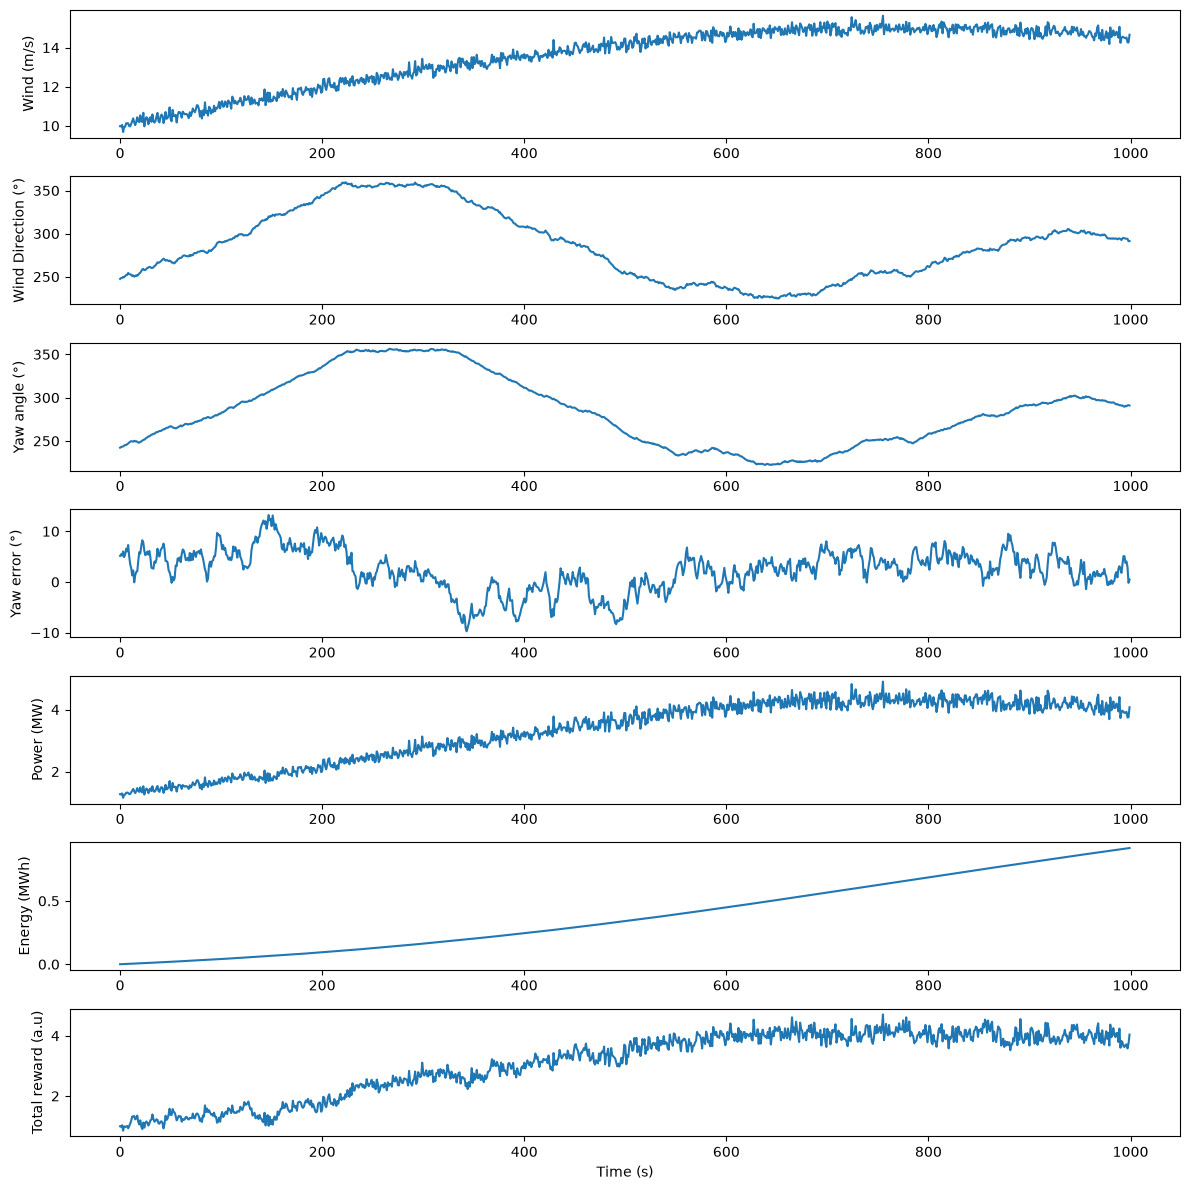

In [8]:
time=np.arange(len(speed))

plt.figure(figsize=(12,12))


plt.subplot(7,1,1)
plt.plot(time,speed)
plt.ylabel("Wind (m/s)")


plt.subplot(7,1,2)
plt.plot(time,direction)
plt.ylabel(r"Wind Direction ($\degree$)")


plt.subplot(7,1,3)
plt.plot(time,yaw)
plt.ylabel(r"Yaw angle ($\degree$)")


plt.subplot(7,1,4)
plt.plot(time,error)
plt.ylabel(r"Yaw error ($\degree$)")


plt.subplot(7,1,5)
plt.plot(time,power)
plt.ylabel("Power (MW)")


plt.subplot(7,1,6)
plt.plot(time,energy)
plt.ylabel("Energy (MWh)")

plt.subplot(7,1,7)
plt.plot(time,total_reward)
plt.ylabel("Total reward (a.u)")

plt.xlabel("Time (s)")


plt.tight_layout()

plt.show()